# Fixed-width window FFD — stationarity d sweep {0.20, 0.25, 0.30}

Agreed setup (see `README.md` §3):

| Item | Setting |
|---|---|
| Method | **Fixed-width window FFD** (López de Prado, Ch. 5): one constant weight vector cut at τ, applied causally to every bar — not expanding-window FD |
| Input | `log(close)`, daily, `data/<SYM>/<SYM>-sorted-1d.parquet` |
| τ | 1e-4 (weight cutoff → window length) |
| Warm-up | 2019-01 → 2020-12, only fills the FFD window |
| Train (ADF) | 2021-01-01 → 2023-12-31 |
| ADF | `regression='c', maxlag=1, autolag=None` |
| Rule | smallest d with p < 0.01 (strict); p < 0.05 shown for reference |

Test data (2024+) is not touched here.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import adfuller

DATA = Path('../../data')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
TAU = 1e-4
D_GRID = [0.20, 0.25, 0.30]
TRAIN = ('2021-01-01', '2023-12-31')
ALPHA_STRICT, ALPHA = 0.01, 0.05

In [2]:
def ffd_weights(d, tau=TAU):
    w = [1.0]                      # lag 0 first
    while True:
        k = len(w)
        nxt = -w[-1] * (d - k + 1) / k
        if abs(nxt) < tau:
            return np.asarray(w)
        w.append(nxt)

def ffd(log_close: pd.Series, d, tau=TAU) -> pd.Series:
    """Causal fixed-width FFD: y_t = sum_k w_k x_{t-k}; NaN until the window is full."""
    w = ffd_weights(d, tau)
    y = np.full(len(log_close), np.nan)
    y[len(w) - 1:] = np.convolve(log_close.values, w, mode='valid')
    return pd.Series(y, index=log_close.index)

def load(sym):
    df = pd.read_parquet(DATA / sym / f'{sym}-sorted-1d.parquet')
    ts = pd.to_datetime(df['timestamp'])
    ts = ts.dt.tz_convert(None) if ts.dt.tz is not None else ts
    s = pd.Series(np.log(df['close'].values), index=ts, name=sym)
    assert s.index.is_monotonic_increasing and s.index.is_unique
    return s

pd.DataFrame({d: [len(ffd_weights(d)), ffd_weights(d).sum()] for d in D_GRID},
             index=['window (bars)', 'weight sum (level kept)']).round(3)

,0.20,0.25,0.30
window (bars),497.000,445.000,388.000
weight sum (level kept),0.248,0.178,0.129


## Data coverage — warm-up must cover the window

In [3]:
px = {s: load(s) for s in ASSETS}
pd.DataFrame({s: {'first bar': x.index[0].date(), 'last bar': x.index[-1].date(),
                  'warm-up bars (<2021)': int((x.index < TRAIN[0]).sum()),
                  'train bars': int(x.loc[TRAIN[0]:TRAIN[1]].size)} for s, x in px.items()}).T

,first bar,last bar,warm-up bars (<2021),train bars
BTC,2019-01-01,2026-10-29,731,1095
ETH,2019-01-01,2026-10-29,731,1095
QQQ,2019-01-02,2026-10-29,505,753
XAUUSD,2019-01-02,2026-10-29,517,773


## ADF sweep on the train window

d = 0 is plain log price (expected to fail).

In [4]:
rows = []
for s, x in px.items():
    for d in [0.0] + D_GRID:
        y = (x if d == 0 else ffd(x, d)).loc[TRAIN[0]:TRAIN[1]]
        missing = int(y.isna().sum()); y = y.dropna()
        stat, p, _, _, crit = adfuller(y, maxlag=1, regression='c', autolag=None)
        rows.append({'asset': s, 'd': d, 'window': 1 if d == 0 else len(ffd_weights(d)),
                     'n': len(y), 'train bars w/o value': missing,
                     'ADF stat': stat, 'crit 1%': crit['1%'], 'crit 5%': crit['5%'], 'p': p,
                     'pass 1%': p < ALPHA_STRICT, 'pass 5%': p < ALPHA,
                     'corr(FFD, log P)': np.corrcoef(y, x.loc[y.index])[0, 1]})
res = pd.DataFrame(rows).set_index(['asset', 'd'])
res.style.format({'ADF stat': '{:.2f}', 'crit 1%': '{:.2f}', 'crit 5%': '{:.2f}', 'p': '{:.4f}',
                  'corr(FFD, log P)': '{:.2f}'})

## Selected d — smallest d in the grid that passes

In [5]:
def pick(col):
    ok = res[res[col]].reset_index()
    ok = ok[ok.d > 0]
    return ok.groupby('asset').d.min().reindex(ASSETS)

sel = pd.DataFrame({'d (p<0.01)': pick('pass 1%'), 'd (p<0.05)': pick('pass 5%')})
sel['window'] = sel['d (p<0.01)'].map(lambda d: len(ffd_weights(d)) if pd.notna(d) else np.nan)
sel['p at chosen d'] = [res.loc[(a, d), 'p'] if pd.notna(d) else np.nan for a, d in sel['d (p<0.01)'].items()]
sel

,d (p<0.01),d (p<0.05),window,p at chosen d
asset,,,,
BTC,0.25,0.2,445,0.006426
ETH,0.25,0.2,445,0.001253
QQQ,0.25,0.2,445,0.003656
XAUUSD,0.20,0.2,497,0.000172


Notes
- If an asset passes at 0.20 already, 0.20 is only the floor of this grid, not the proven minimum.
- ADF rejection is evidence against a unit root under this specification, not proof of stationarity.
- `corr(FFD, log P)` shows how much of the price level the feature still carries (memory kept).

## Plot — log price vs FFD at the selected d (train shaded)

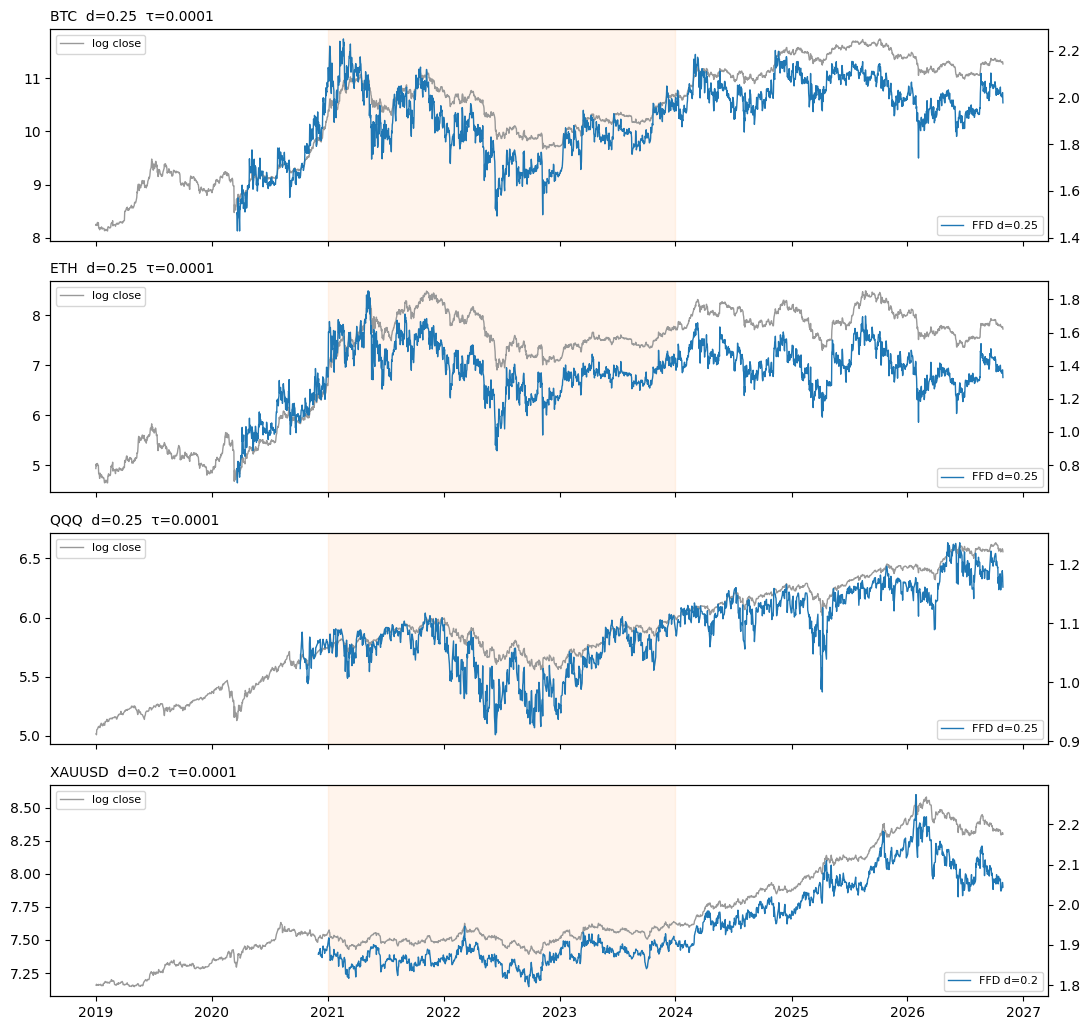

In [6]:
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    d = sel.loc[s, 'd (p<0.01)']
    x = px[s].loc['2019':]; y = ffd(px[s], d)
    ax.plot(x.index, x, color='0.6', lw=1, label='log close')
    ax2 = ax.twinx(); ax2.plot(y.index, y, color='tab:blue', lw=1, label=f'FFD d={d}')
    ax.axvspan(pd.Timestamp(TRAIN[0]), pd.Timestamp(TRAIN[1]), color='tab:orange', alpha=0.08)
    ax.set_title(f'{s}  d={d}  τ={TAU:g}', loc='left', fontsize=10)
    ax.legend(loc='upper left', fontsize=8); ax2.legend(loc='lower right', fontsize=8)
plt.tight_layout()

## Conclusion — chosen setting (decided 2026-10-31)

**Fixed-width window FFD on `log(close)`, τ = 1e-4, d = 0.25 for all four assets → 445-bar window.**

| Asset | Smallest d passing ADF at p < 0.01 (grid 0.20 / 0.25 / 0.30) | ADF p at d = 0.25 | corr(FFD, log P) at d = 0.25 |
|---|---:|---:|---:|
| BTC | 0.25 | 0.006 | 0.86 |
| ETH | 0.25 | 0.001 | 0.71 |
| QQQ | 0.25 | 0.004 | 0.88 |
| XAUUSD | 0.20 | < 0.0001 | 0.89 |

- d = 0.25 is the smallest d that passes at 1% for BTC, ETH and QQQ. At 0.20 they pass only at 5%, which is borderline.
- One shared d gives all assets the same weights and window, so the FFD and Z features are directly comparable. Gold gets slightly more differencing than its minimum (0.20).
- Selected on train 2021-01-01 → 2023-12-31, warm-up 2019–2020. Test data (2024+) was not used.
- Next (Stage A): check whether d = 0.25 holds over time with a rolling one-year ADF, and track the FFD mean and σ.